# 02 · Modelamiento, optimización y análisis de generalización

Flujo del notebook:

1. División estratificada 80/20 (la prueba queda aislada).
2. Decisión sobre `Weight` y `Height` (escenarios con y sin ellas).
3. Línea base: tres modelos con hiperparámetros por defecto.
4. Optimización con **Grid Search** y **Random Search** (CV estratificada de 5 folds, métrica F1 macro).
5. Evaluación en prueba y comparación.
6. Generalización: riesgo empírico vs. real, curvas de aprendizaje y de validación, estabilidad y pruebas estadísticas.

> Ejecutar este notebook completo tarda unos 5 minutos y regenera los modelos de `models/`
> y los resultados de `results/`. Con la semilla fija (42), los resultados son los mismos en cada ejecución.

In [1]:
import sys
from pathlib import Path

# Localiza la raíz del proyecto (carpeta que contiene src/) y la agrega al path
ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

from src import config as C
FIG = C.FIG_DIR
def show(name, width=900):
    display(Image(filename=str(FIG / name), width=width))

## 1. División de los datos

In [2]:
from src import pipeline
df_raw, df, train_df, test_df = pipeline.step_data()
print("Entrenamiento:", train_df.shape, " Prueba:", test_df.shape)
pd.DataFrame({
    "train %": train_df[C.TARGET].value_counts(normalize=True).reindex(C.CLASS_ORDER) * 100,
    "test %": test_df[C.TARGET].value_counts(normalize=True).reindex(C.CLASS_ORDER) * 100,
}).round(2)

Entrenamiento: (1669, 17)  Prueba: (418, 17)


,train %,test %
NObeyesdad,,
Insufficient_Weight,12.82,12.68
Normal_Weight,13.48,13.64
Overweight_Level_I,13.24,13.16
Overweight_Level_II,13.90,13.88
Obesity_Type_I,16.84,16.75
Obesity_Type_II,14.20,14.35
Obesity_Type_III,15.52,15.55


La estratificación conserva las proporciones de clase en ambos conjuntos. Desde este punto, **el conjunto
de prueba no se usa para ninguna decisión**: solo se emplea al final para estimar el rendimiento real.

## 2. Escenario con y sin Weight / Height (validación cruzada sobre entrenamiento)

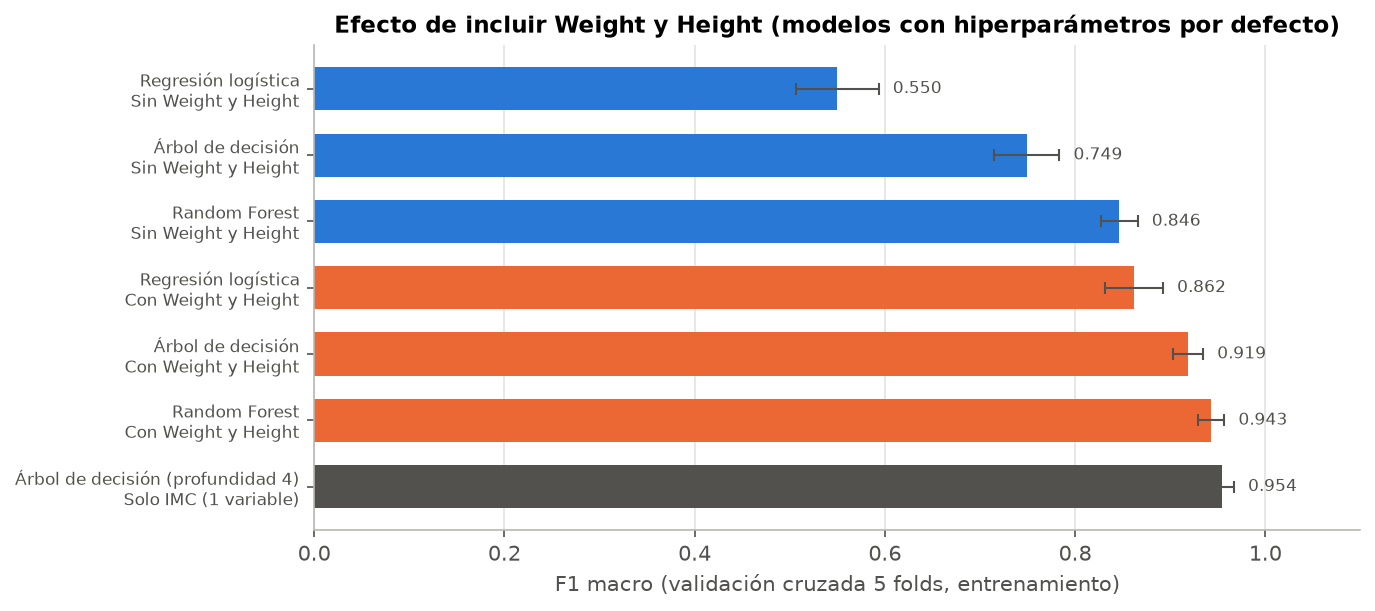

,escenario,modelo,f1_macro_cv_media,f1_macro_cv_std
0,Sin Weight y Height (principal),Regresión logística,0.5497,0.0436
1,Sin Weight y Height (principal),Árbol de decisión,0.7492,0.0341
2,Sin Weight y Height (principal),Random Forest,0.8464,0.0192
3,Con Weight y Height,Regresión logística,0.8616,0.0306
4,Con Weight y Height,Árbol de decisión,0.9188,0.0156
5,Con Weight y Height,Random Forest,0.9432,0.0135
6,Solo IMC (1 variable),Árbol de decisión (profundidad 4),0.9539,0.0129


In [3]:
from src import leakage
scen = leakage.scenario_comparison(train_df)
leakage.plot_scenarios(scen); show("09_escenarios_peso_estatura.png", 800)
scen

- Al agregar `Weight` y `Height`, la regresión logística pasa de F1 ≈ 0,55 a ≈ 0,86, y el Random Forest de ≈ 0,85 a ≈ 0,94.
- Un árbol que usa **solo el IMC** (una única variable derivada de peso y estatura) obtiene F1 ≈ 0,95,
  **más que cualquier modelo con las 16 variables**.

Esto confirma que la información de la etiqueta está en el IMC. **Decisión metodológica:** el escenario
principal **excluye `Weight` y `Height`** y predice el nivel de obesidad a partir de hábitos y datos
demográficos. El problema es más difícil, pero es el que tiene sentido para medir generalización y el que
tendría utilidad práctica (por ejemplo, identificar perfiles de riesgo a partir de una encuesta de hábitos).

## 3–4. Línea base y optimización de hiperparámetros

In [4]:
import json
from src.models import GRID_SPACES, RANDOM_SPACES, N_ITER
for name in GRID_SPACES:
    print(name, "| Random Search n_iter =", N_ITER[name])
    print("  Grid:", GRID_SPACES[name])

Regresión logística | Random Search n_iter = 20
  Grid: [{'clf__solver': ['lbfgs'], 'clf__l1_ratio': [0.0], 'clf__C': [0.01, 0.1, 1, 10, 100]}, {'clf__solver': ['saga'], 'clf__l1_ratio': [0.0, 0.5, 1.0], 'clf__C': [0.01, 0.1, 1, 10, 100]}]
Árbol de decisión | Random Search n_iter = 40
  Grid: {'clf__criterion': ['gini', 'entropy'], 'clf__max_depth': [3, 5, 8, 12, None], 'clf__min_samples_split': [2, 10, 20], 'clf__min_samples_leaf': [1, 5, 10]}
Random Forest | Random Search n_iter = 30
  Grid: {'clf__n_estimators': [100, 300], 'clf__max_depth': [10, 20, None], 'clf__min_samples_split': [2, 5], 'clf__min_samples_leaf': [1, 2], 'clf__max_features': ['sqrt', 'log2']}


In [5]:
m = pipeline.step_modeling(train_df, test_df)   # baseline + Grid Search + Random Search
m["summary"]

  Regresión logística  Grid Search    F1 CV = 0.5551  (20 combinaciones, 30.2 s)


  Regresión logística  Random Search  F1 CV = 0.5552  (20 combinaciones, 35.3 s)


  Árbol de decisión    Grid Search    F1 CV = 0.7492  (90 combinaciones, 8.0 s)


  Árbol de decisión    Random Search  F1 CV = 0.7019  (40 combinaciones, 3.6 s)


  Random Forest        Grid Search    F1 CV = 0.8541  (48 combinaciones, 67.7 s)


  Random Forest        Random Search  F1 CV = 0.8391  (30 combinaciones, 52.3 s)


,modelo,metodo,combinaciones,tiempo_s,f1_train_cv,f1_cv_media,f1_cv_std,mejores_hiperparametros,seleccionado
0,Regresión logística,Por defecto (sin optimizar),1,NaN,0.5725,0.5497,0.0436,por defecto,False
1,Regresión logística,Grid Search,20,30.2,0.5781,0.5551,0.0408,"{'C': 100, 'l1_ratio': 0.0, 'solver': 'lbfgs'}",False
2,Regresión logística,Random Search,20,35.3,0.5779,0.5552,0.0415,"{'C': np.float64(793.2048), 'l1_ratio': 0.0, '...",True
3,Árbol de decisión,Por defecto (sin optimizar),1,NaN,1.0000,0.7492,0.0341,por defecto,False
4,Árbol de decisión,Grid Search,90,8.0,1.0000,0.7492,0.0341,"{'criterion': 'gini', 'max_depth': None, 'min_...",True
5,Árbol de decisión,Random Search,40,3.6,0.8320,0.7019,0.0356,"{'criterion': 'gini', 'max_depth': 9, 'min_sam...",False
6,Random Forest,Por defecto (sin optimizar),1,NaN,1.0000,0.8464,0.0192,por defecto,False
7,Random Forest,Grid Search,48,67.7,0.9922,0.8541,0.0149,"{'max_depth': 20, 'max_features': 'sqrt', 'min...",True
8,Random Forest,Random Search,30,52.3,0.9696,0.8391,0.0120,"{'max_depth': 18, 'max_features': 'sqrt', 'min...",False


**Lectura de la tabla** (todo medido con CV de 5 folds sobre entrenamiento):

- **Regresión logística:** ambas búsquedas eligen una regularización muy débil (C grande, L2). La mejora
  sobre el modelo por defecto es mínima (0,550 → 0,555). La limitación no es la regularización, sino la
  **frontera lineal**: el modelo está en régimen de **subajuste**.
- **Árbol de decisión:** Grid Search selecciona un árbol **sin límite de profundidad**, idéntico al modelo
  por defecto. Random Search encontró un árbol podado (profundidad 9) con F1 menor (0,702). Restringir el
  árbol reduce la brecha, pero también el F1 de validación.
- **Random Forest:** Grid Search mejora levemente al modelo por defecto (0,846 → 0,854) con
  `max_depth=20`, `min_samples_split=5` y 300 árboles. Random Search quedó por debajo (0,839).

En todos los casos se selecciona la configuración con **mayor F1 en validación cruzada**, nunca la de prueba.

## 5. Evaluación en el conjunto de prueba

In [6]:
ev = pipeline.step_evaluation(m)
ev["comparacion"]

,modelo,busqueda_seleccionada,accuracy_train,accuracy_test,precision_test,recall_test,f1_train,f1_cv_media,f1_cv_std,f1_test,brecha_train_test_f1,brecha_train_cv_f1
0,Regresión logística,Random Search,0.6022,0.5861,0.5748,0.5722,0.5784,0.5552,0.0415,0.5487,0.0297,0.0232
1,Árbol de decisión,Grid Search,1.0000,0.7297,0.7249,0.7285,1.0000,0.7492,0.0341,0.7238,0.2762,0.2508
2,Random Forest,Grid Search,0.9910,0.8565,0.8578,0.8527,0.9909,0.8541,0.0149,0.8520,0.1388,0.1368


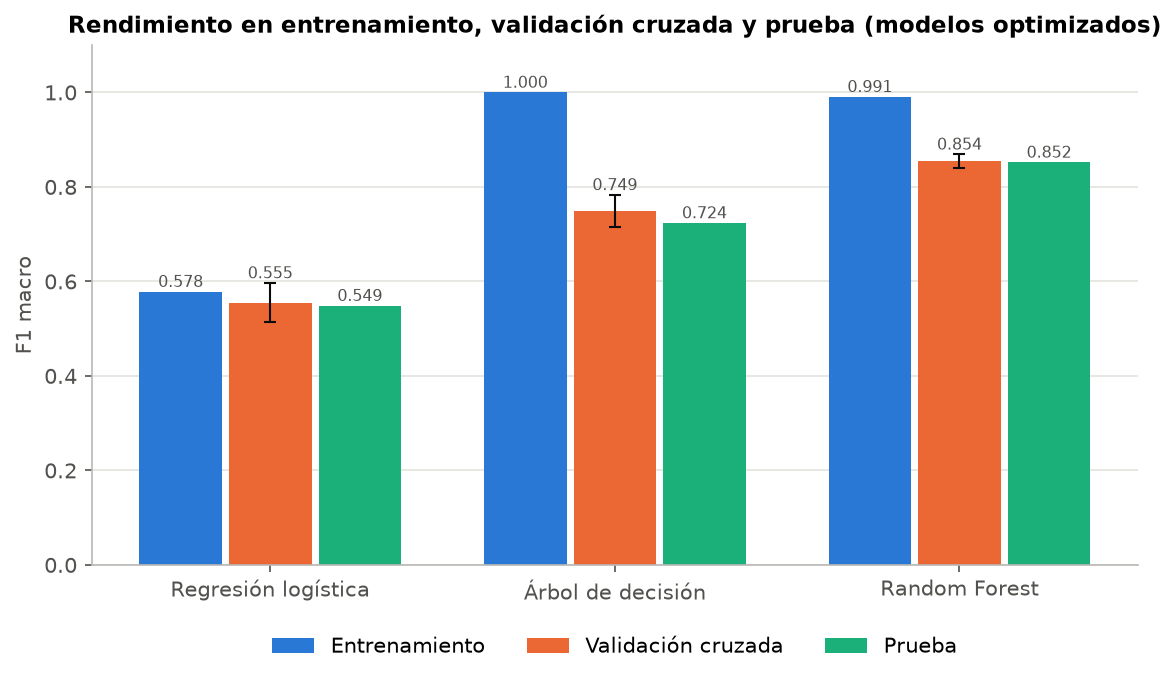

In [7]:
show("11_train_cv_test.png", 800)

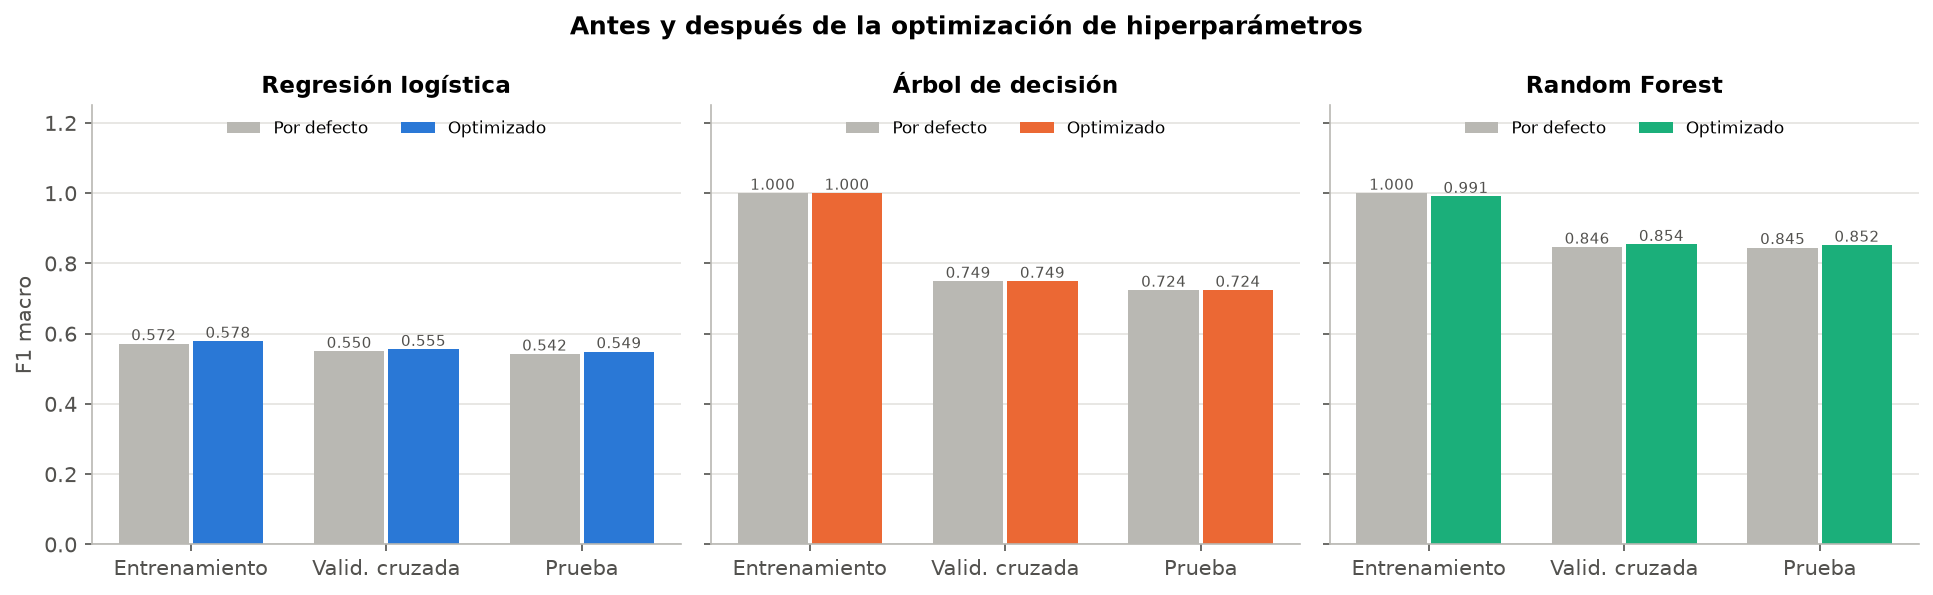

In [8]:
show("12_antes_despues_optimizacion.png")

In [9]:
ev["antes_despues"]

,modelo,version,f1_train,f1_cv,f1_test,accuracy_test,brecha_train_test
0,Regresión logística,Por defecto,0.5715,0.5497,0.5420,0.5837,0.0295
1,Regresión logística,Optimizado,0.5784,0.5552,0.5487,0.5861,0.0297
2,Árbol de decisión,Por defecto,1.0000,0.7492,0.7238,0.7297,0.2762
3,Árbol de decisión,Optimizado,1.0000,0.7492,0.7238,0.7297,0.2762
4,Random Forest,Por defecto,1.0000,0.8464,0.8452,0.8493,0.1548
5,Random Forest,Optimizado,0.9909,0.8541,0.8520,0.8565,0.1388


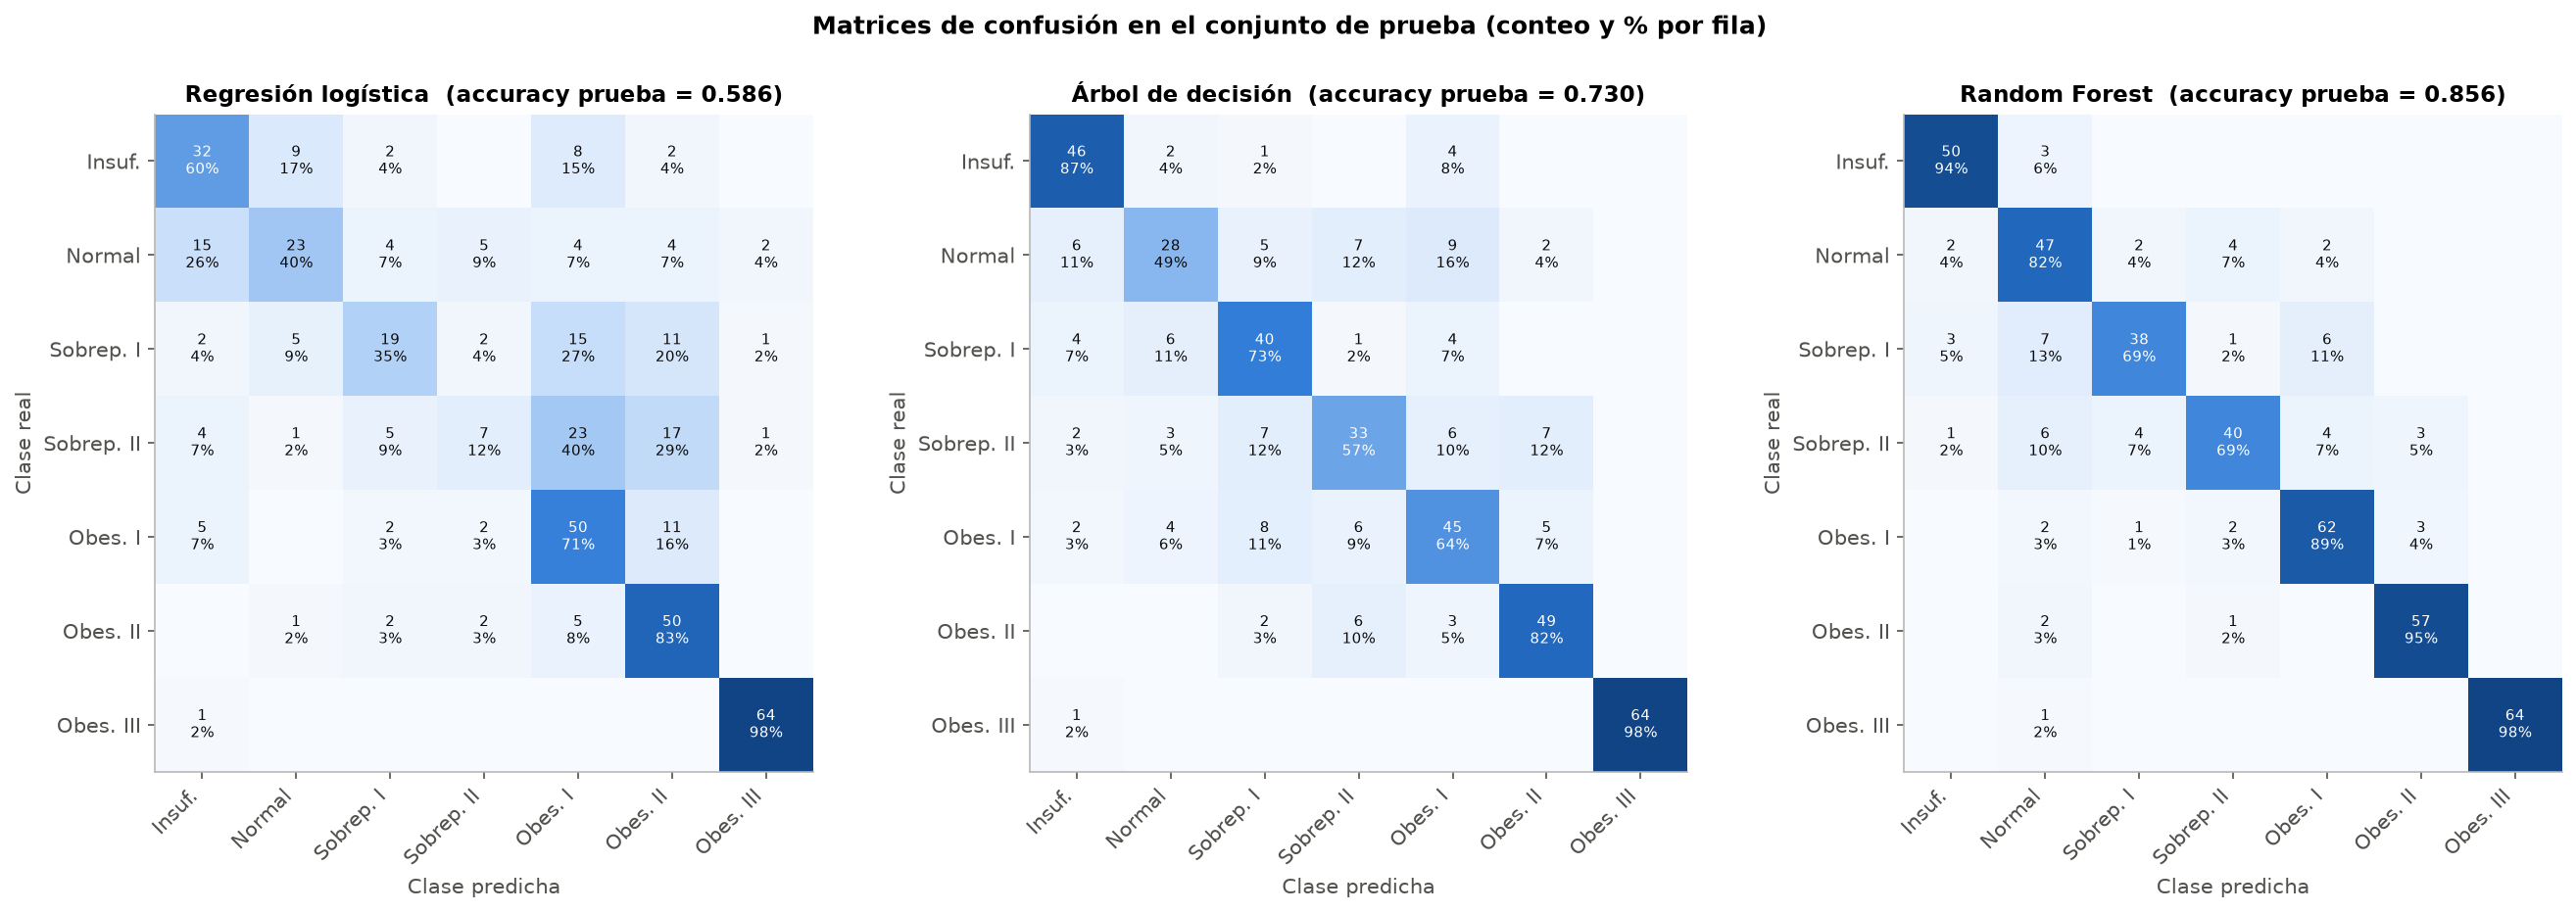

In [10]:
show("10_matrices_confusion.png")

In [11]:
ev["por_clase"].pivot(index="clase", columns="modelo", values="f1-score").reindex(C.CLASS_ORDER)

modelo,Random Forest,Regresión logística,Árbol de decisión
clase,,,
Insufficient_Weight,0.9174,0.5714,0.8070
Normal_Weight,0.7520,0.4792,0.5600
Overweight_Level_I,0.7600,0.4270,0.6780
Overweight_Level_II,0.7547,0.1842,0.5946
Obesity_Type_I,0.8611,0.5714,0.6383
Obesity_Type_II,0.9268,0.6452,0.7967
Obesity_Type_III,0.9922,0.9624,0.9922


- **Random Forest** obtiene el mejor desempeño en prueba (accuracy 0,857, F1 macro 0,852), muy cercano a
  su estimación por CV (0,854). Esto indica que la CV fue una estimación fiable del riesgo real.
- El **árbol de decisión** tiene F1 = 1,0 en entrenamiento, pero solo 0,724 en prueba: memoriza el conjunto
  de entrenamiento (**sobreajuste**, varianza alta).
- La **regresión logística** tiene la menor brecha (0,03), pero un rendimiento bajo en todos los conjuntos
  (≈ 0,55–0,58): **subajuste**, sesgo alto.
- Las clases extremas (*Insufficient_Weight*, *Obesity_Type_II/III*) son las más fáciles de clasificar.
  Los errores se concentran en clases **vecinas** (Normal ↔ Sobrepeso I ↔ Sobrepeso II), cuyos perfiles
  de hábitos se parecen.

## 6. Generalización y sobreajuste

In [12]:
g = pipeline.step_generalization(m)
g["riesgos"]

,modelo,riesgo_empirico,riesgo_cv,riesgo_prueba,brecha_generalizacion
0,Regresión logística,0.3978,0.4207,0.4139,0.0160
1,Árbol de decisión,0.0000,0.2444,0.2703,0.2703
2,Random Forest,0.0090,0.1426,0.1435,0.1346


Con la pérdida 0-1, el **riesgo empírico** es la tasa de error en entrenamiento y el error de prueba estima
el **riesgo real**. El árbol tiene riesgo empírico 0 y riesgo de prueba 0,27, así que su brecha es la
mayor. El Random Forest tiene un riesgo empírico casi nulo (0,009) y el menor riesgo real (0,14). La
regresión logística tiene la menor brecha (0,016), pero su riesgo real es el más alto (0,41).
**Una brecha pequeña no implica un buen modelo**: también importa el nivel del riesgo real.

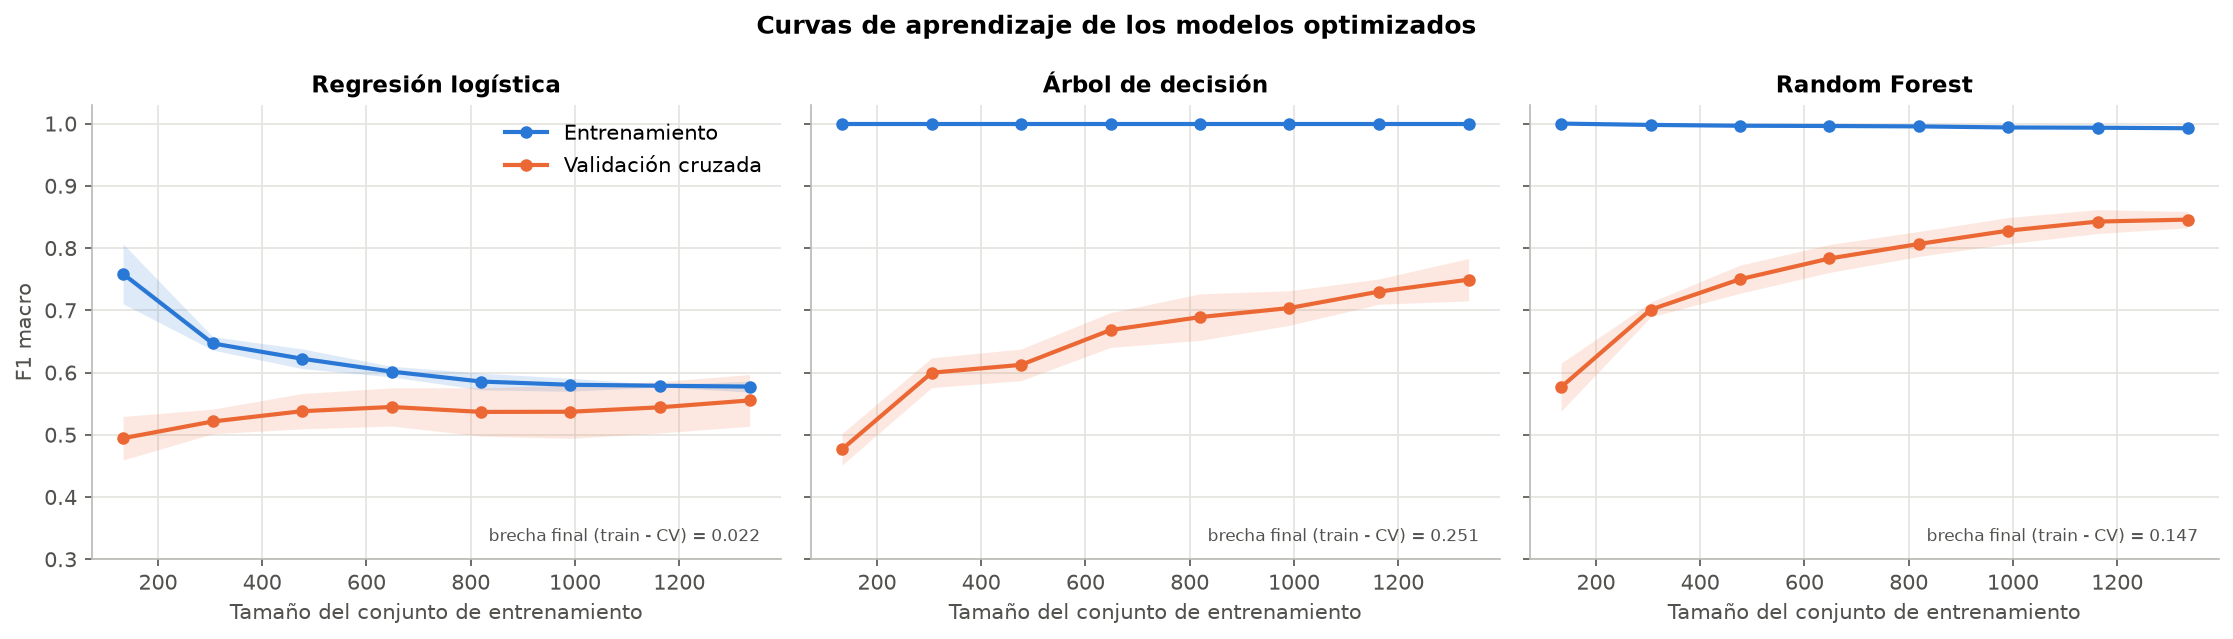

In [13]:
show("13_curvas_aprendizaje.png")

- **Regresión logística:** las curvas convergen rápido hacia ≈ 0,56. Agregar más datos no ayudaría: el
  límite es el **sesgo** del modelo lineal.
- **Árbol:** la curva de entrenamiento se mantiene en 1,0 y la de validación sube lentamente. La brecha
  grande y persistente es típica de un modelo de **alta varianza**.
- **Random Forest:** la curva de validación crece de forma sostenida (0,58 → 0,85) y la brecha se reduce
  con más datos, aunque todavía no se estabiliza por completo: más datos probablemente lo mejorarían algo.

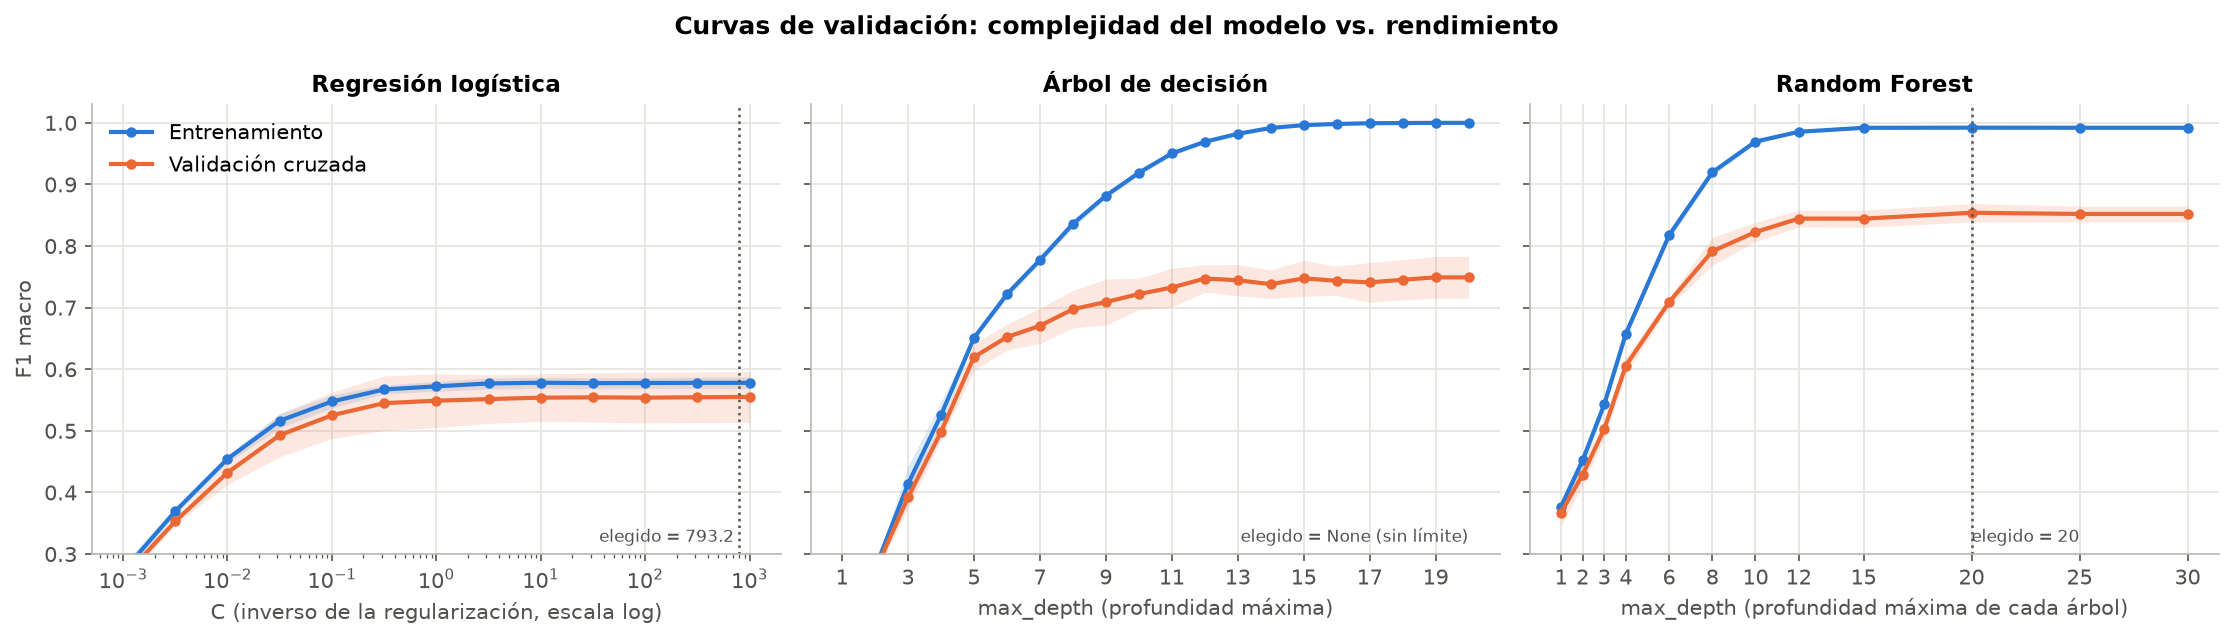

In [14]:
show("14_curvas_validacion.png")

Las curvas de validación muestran la relación **complejidad ↔ generalización**:

- En la regresión logística, una regularización fuerte (C pequeño) produce subajuste. A partir de C ≈ 1
  la curva es plana: el modelo ya alcanzó su capacidad máxima.
- En el árbol, aumentar la profundidad hace que el F1 de entrenamiento llegue a 1,0, mientras que el de
  validación se estanca en ≈ 0,74–0,75 desde profundidad 12. La brecha crece con la complejidad.
- En el Random Forest, la validación sube hasta profundidad ≈ 12–20 y luego se estabiliza: el promedio de
  muchos árboles **controla la varianza** que tendría un árbol profundo aislado.

## 7. Estabilidad y comparación estadística

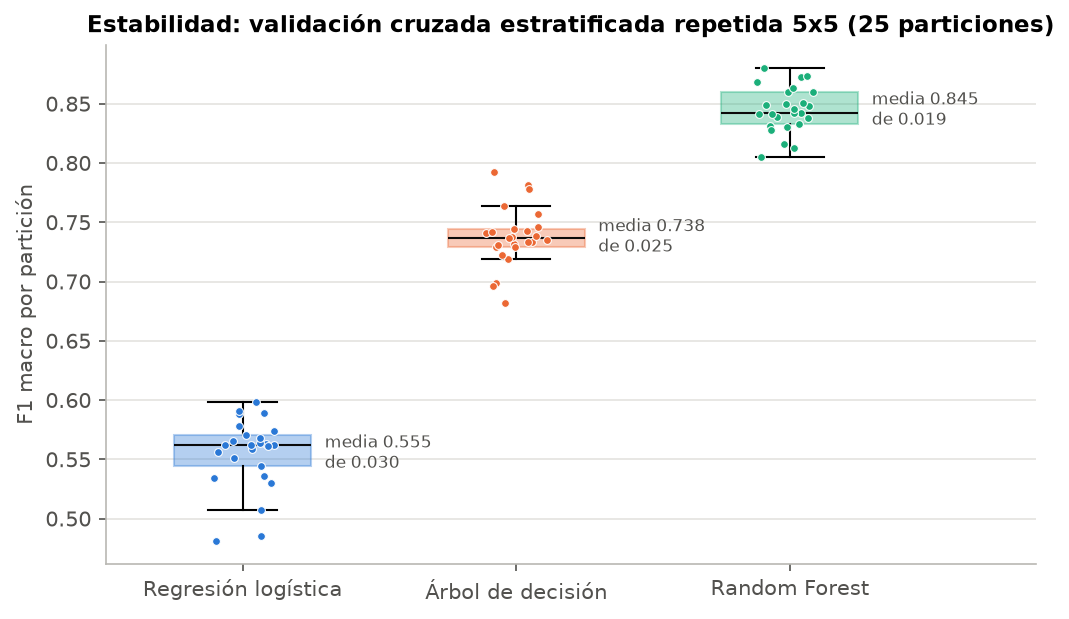

,modelo,mean,std,min,max,coef_variacion_%
0,Regresión logística,0.5552,0.0298,0.4813,0.5981,5.3625
1,Árbol de decisión,0.7377,0.0250,0.6817,0.7923,3.3894
2,Random Forest,0.8447,0.0189,0.8048,0.8799,2.2403


In [15]:
show("15_estabilidad_cv_repetida.png", 700)
pd.read_csv(C.TAB_DIR / "cv_repetida_resumen.csv")

In [16]:
g["t_test"]

,modelo_A,modelo_B,diferencia_media_F1,t_corregido,p_valor,significativo_5%
0,Regresión logística,Árbol de decisión,-0.1825,-9.6785,0.0,True
1,Regresión logística,Random Forest,-0.2895,-21.5923,0.0,True
2,Árbol de decisión,Random Forest,-0.1070,-8.4985,0.0,True


In [17]:
g["mcnemar"]

,modelo_A,modelo_B,A_acierta_B_falla,A_falla_B_acierta,p_valor,significativo_5%
0,Regresión logística,Árbol de decisión,38,98,0.0,True
1,Regresión logística,Random Forest,8,121,0.0,True
2,Árbol de decisión,Random Forest,17,70,0.0,True


In [18]:
g["ic_bootstrap"]

,modelo,accuracy,accuracy_IC95_inf,accuracy_IC95_sup,f1_macro,f1_IC95_inf,f1_IC95_sup
0,Regresión logística,0.5861,0.5383,0.6316,0.5487,0.5016,0.5919
1,Árbol de decisión,0.7297,0.6890,0.7703,0.7238,0.6824,0.7640
2,Random Forest,0.8565,0.8206,0.8900,0.8520,0.8143,0.8837


- **Estabilidad:** en 25 particiones (CV 5×5), el Random Forest tiene la menor desviación (0,019) y el menor
  coeficiente de variación (2,2 %).
- **t-test corregido de Nadeau-Bengio** (sobre la CV repetida): todas las diferencias entre modelos son
  significativas (p < 0,001). El t-test clásico no es válido aquí porque los folds comparten observaciones.
  La corrección infla la varianza para tenerlo en cuenta.
- **McNemar (prueba):** el Random Forest acierta en 121 casos en que la regresión logística falla, frente a
  8 casos en el sentido contrario. Frente al árbol, la proporción es de 70 a 17. Las diferencias son
  significativas.
- **IC 95 % bootstrap:** los intervalos de F1 en prueba no se solapan entre modelos
  (RF 0,81–0,88; árbol 0,68–0,76; RL 0,50–0,59).

## 8. Importancia de las variables

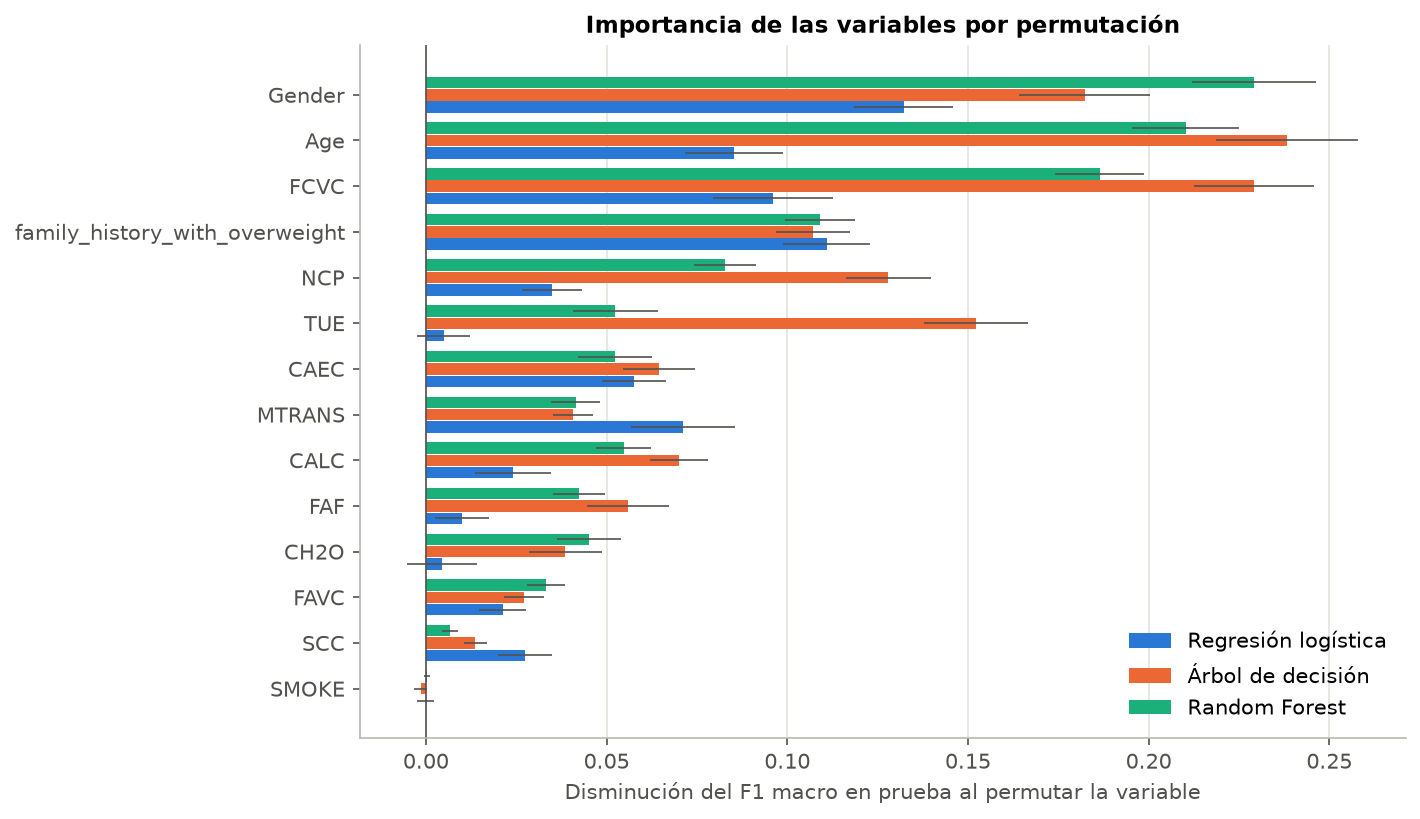

In [19]:
show("16_importancia_permutacion.png", 800)

Para el Random Forest, las variables más influyentes son `Gender`, `Age`, `FCVC` (verduras) y
`family_history_with_overweight`. La importancia de `Gender` debe interpretarse con cautela por el
artefacto sintético descrito en el EDA. `SMOKE` no aporta información.

## 9. Conclusión del modelamiento

El **Random Forest** (Grid Search: 300 árboles, `max_depth=20`, `min_samples_split=5`,
`min_samples_leaf=1`, `max_features="sqrt"`) es el modelo seleccionado. Tiene el menor riesgo real
estimado, una estimación por CV que coincide con la de prueba, la mayor estabilidad y diferencias
estadísticamente significativas frente a los otros dos modelos. Su brecha entrenamiento–prueba (≈ 0,14)
no se debe a un error de estimación, sino a que el ensamble interpola el conjunto de entrenamiento. Lo que
determina su capacidad de generalización es el riesgo de validación y de prueba, y en ambos es el mejor.

El modelo final está guardado en `models/random_forest.joblib`.

In [20]:
import joblib
modelo = joblib.load(C.MODELS_DIR / "random_forest.joblib")
ejemplo = test_df.drop(columns=[C.TARGET, "Height", "Weight"]).head(5)
pd.DataFrame({"real": test_df[C.TARGET].head(5), "predicho": modelo.predict(ejemplo)})

,real,predicho
0,Overweight_Level_II,Overweight_Level_II
1,Obesity_Type_I,Obesity_Type_I
2,Obesity_Type_III,Obesity_Type_III
3,Overweight_Level_I,Overweight_Level_I
4,Obesity_Type_I,Obesity_Type_I
